In [1]:
#Supervised ML

#DATASET UNDERSTANDING

In [131]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder, StandardScaler

%matplotlib inline
sns.set(style="whitegrid")

In [133]:
df = pd.read_csv('online_shoppers_intention.csv')
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [135]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [137]:
df.describe(include='all')

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462,10422
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


In [139]:
df.shape

(12330, 18)

In [141]:
df_original = pd.read_csv('online_shoppers_intention.csv')
print('Total rows:', len(df_original))
print('Duplicate rows:', df_original.duplicated().sum())

Total rows: 12330
Duplicate rows: 125


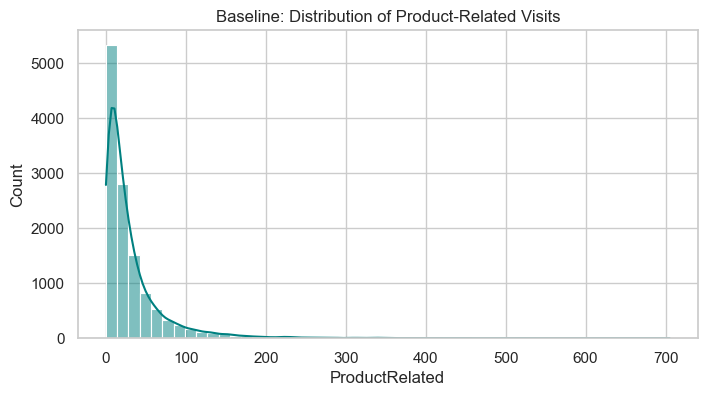

In [143]:
#INITIAL EDA (Baseline)
plt.figure(figsize=(8, 4))
sns.histplot(df['ProductRelated'], bins=50, kde=True, color='teal')
plt.title('Baseline: Distribution of Product-Related Visits')
plt.show()

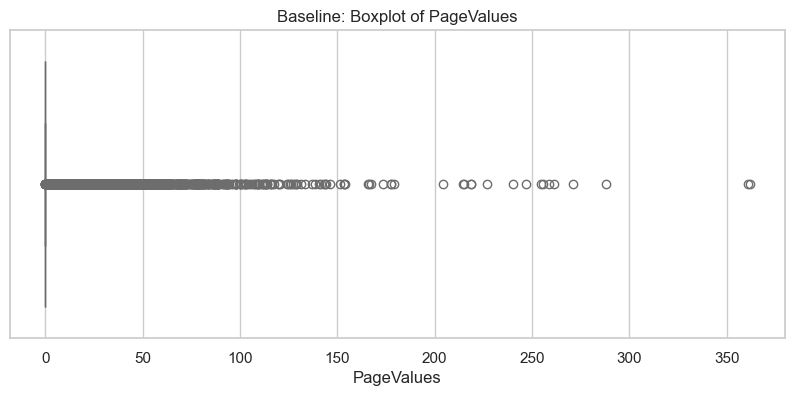

In [144]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['PageValues'], color='salmon')
plt.title('Baseline: Boxplot of PageValues')
plt.show()

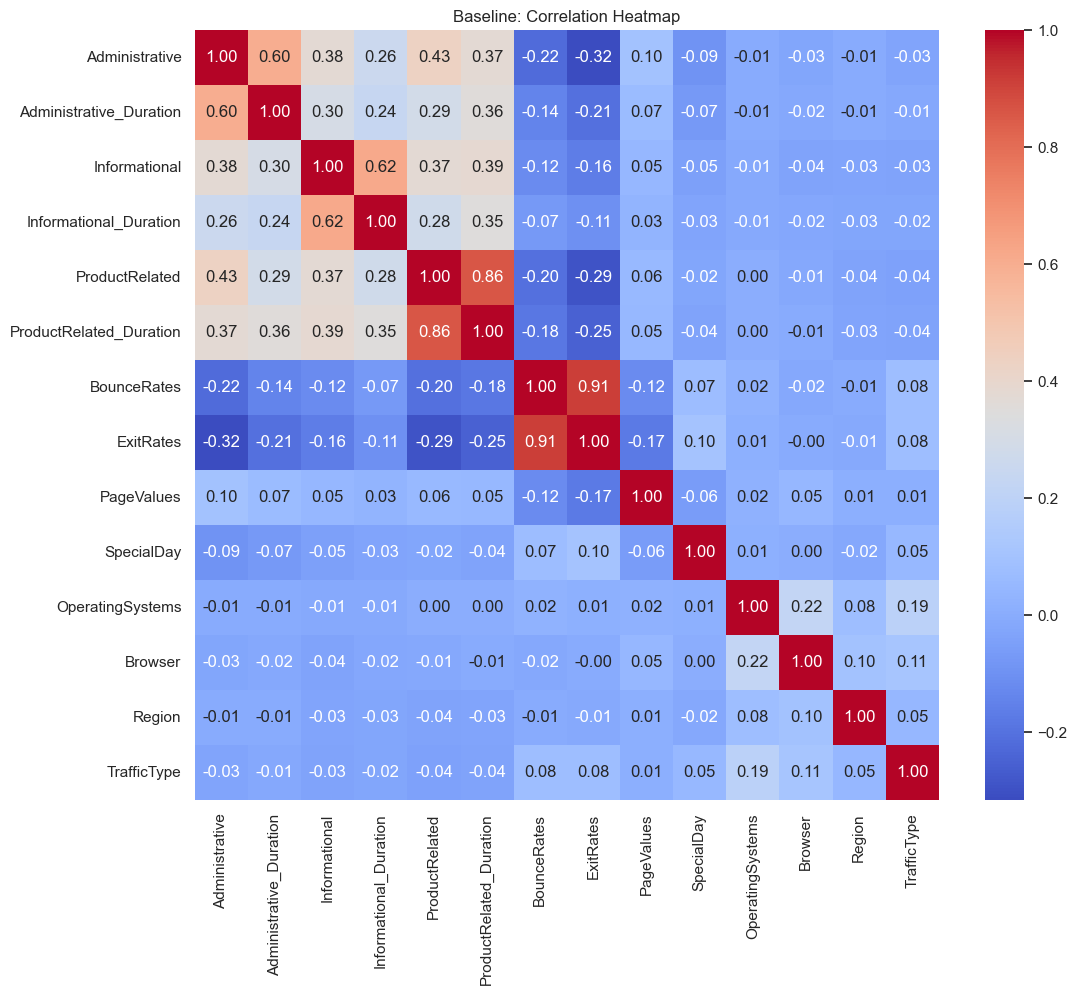

In [146]:
#correlation
plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Baseline: Correlation Heatmap')
plt.show()

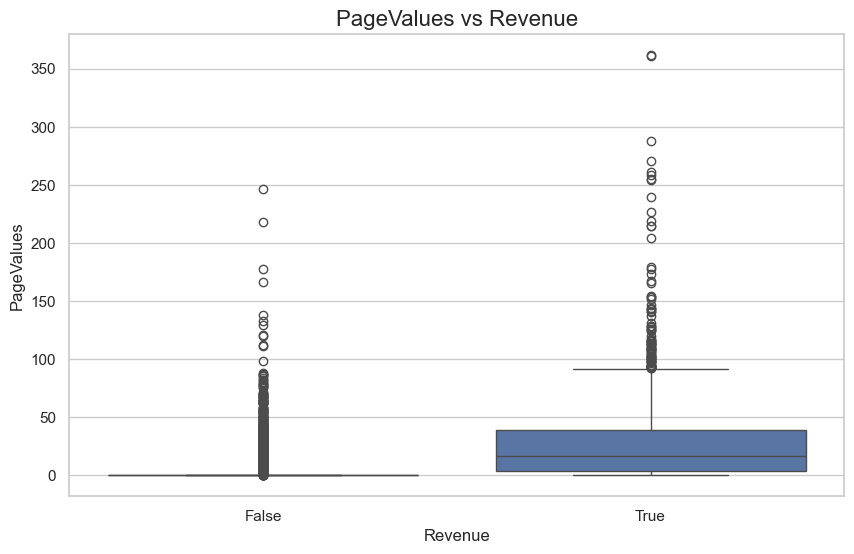

In [148]:
# Relationship

plt.figure(figsize=(10, 6))

sns.boxplot(
    x='Revenue',
    y='PageValues',
    data=df
)

plt.title('PageValues vs Revenue', fontsize=16)
plt.xlabel('Revenue', fontsize=12)
plt.ylabel('PageValues', fontsize=12)

plt.show()

In [149]:
#MISSING VALUE ANALYSIS
print("Natural Missing Values:")
print(df.isnull().sum())

Natural Missing Values:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


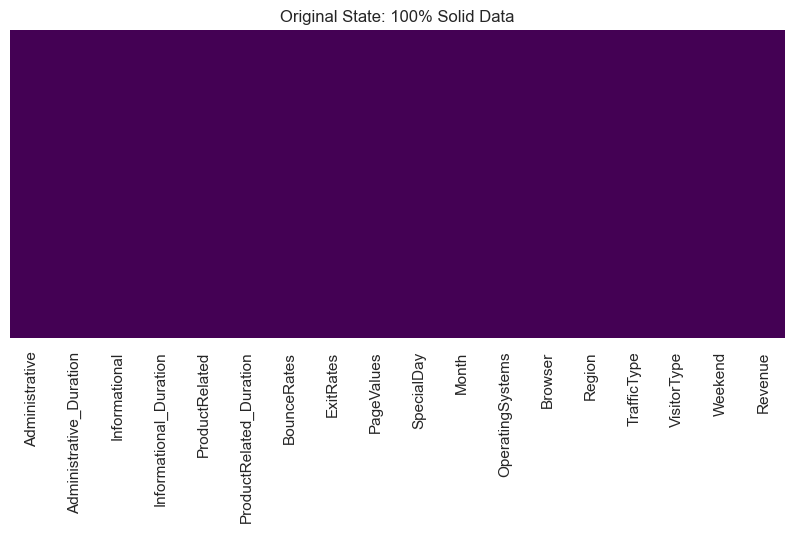

In [150]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Original State: 100% Solid Data')
plt.show()

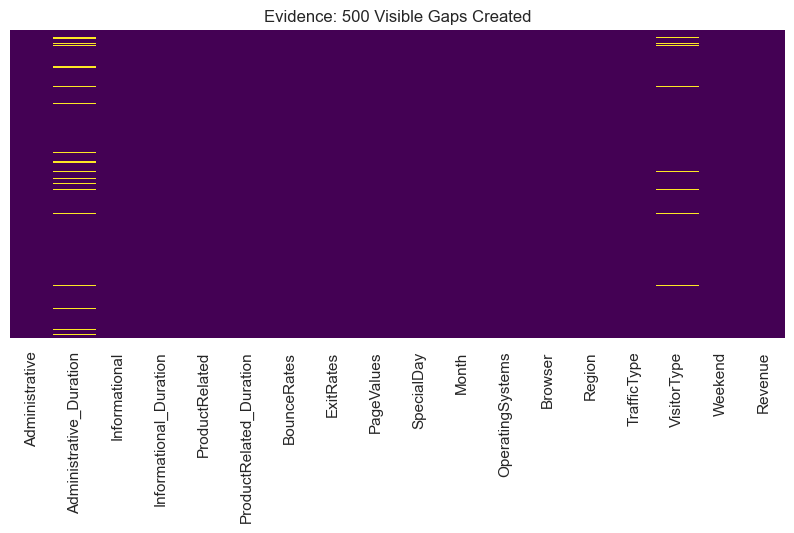

In [152]:
#Add missing values
df_broken = df.copy()
np.random.seed(42)
indices = np.random.choice(df_broken.index, 500, replace=False)
df_broken.loc[indices, 'Administrative_Duration'] = np.nan
df_broken.loc[indices[:200], 'VisitorType'] = np.nan

plt.figure(figsize=(10, 4))
sns.heatmap(df_broken.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Evidence: 500 Visible Gaps Created')
plt.show()

In [153]:
print(df_broken.isnull().sum())

Administrative               0
Administrative_Duration    500
Informational                0
Informational_Duration       0
ProductRelated               0
ProductRelated_Duration      0
BounceRates                  0
ExitRates                    0
PageValues                   0
SpecialDay                   0
Month                        0
OperatingSystems             0
Browser                      0
Region                       0
TrafficType                  0
VisitorType                200
Weekend                      0
Revenue                      0
dtype: int64


In [156]:
#handle missing vules
df_broken['Administrative_Duration'] = df_broken['Administrative_Duration'].fillna(df_broken['Administrative_Duration'].median())
df_broken['VisitorType'] = df_broken['VisitorType'].fillna(df_broken['VisitorType'].mode()[0])
df = df_broken # Healing accepted
print("Data Healed with Median/Mode.")

Data Healed with Median/Mode.


In [157]:
print(df_broken.isnull().sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


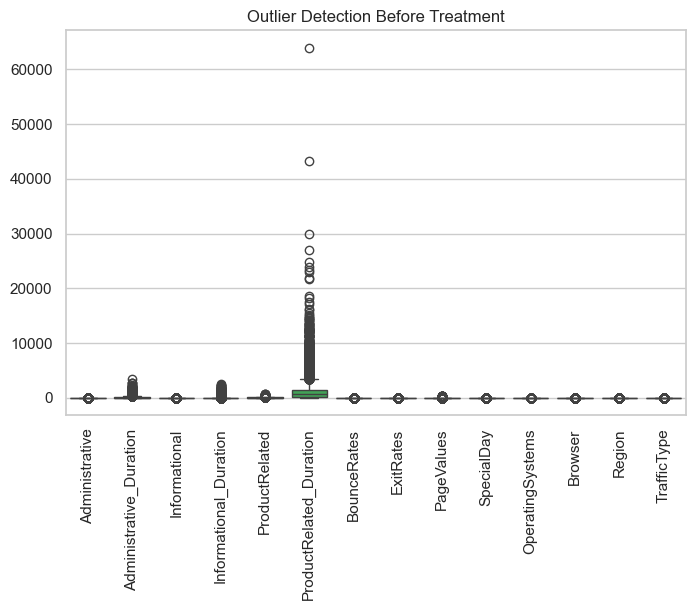

In [159]:
#Outlier Detection Before Treatment (IQR)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Select only numerical columns
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df.select_dtypes(include=np.number)
)

plt.title("Outlier Detection Before Treatment")
plt.xticks(rotation=90)

plt.show()

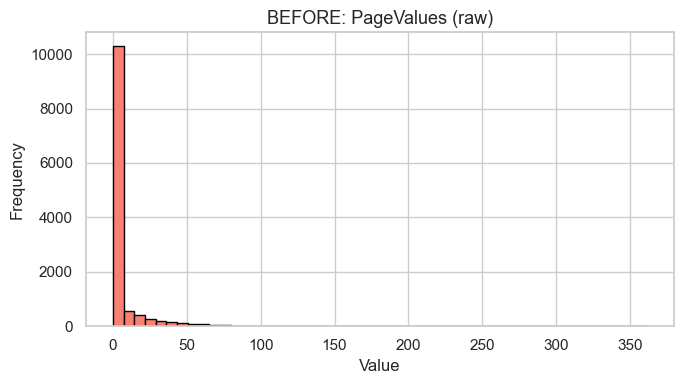

In [160]:
#BEFORE: log1p Transformed PageValues Distribution

plt.figure(figsize=(7, 4))

plt.hist(df_original['PageValues'], bins=50,
         color='salmon', edgecolor='black')

plt.title('BEFORE: PageValues (raw)', fontsize=13)
plt.xlabel('Value')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [161]:
# ============================================
# PHASE 4.5 — OUTLIER CAPPING & ZERO-INFLATED TRANSFORMATION
# ============================================

import numpy as np

# -------------------------------------------------
# STEP 1: Cap outliers (for non-zero-inflated features)
# -------------------------------------------------

def cap_outliers_iqr(df, columns, multiplier=1.5):
    """Cap outliers using IQR method"""
    df_capped = df.copy()
    
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - multiplier * IQR
        upper_bound = Q3 + multiplier * IQR
        
        original_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
        
        # Cap the values
        df_capped[col] = df[col].clip(lower=lower_bound, upper=upper_bound)
        
        print(f"{col}: {original_outliers} outliers capped")
    
    return df_capped

# These features have outliers that should be capped
outlier_cols = [
    'Administrative_Duration',
    'ProductRelated_Duration',
    'ProductRelated',
    'Administrative'
]

df = cap_outliers_iqr(df, outlier_cols, multiplier=1.5)
print("✅ Outlier capping completed.\n")

# -------------------------------------------------
# STEP 2: Transform zero-inflated features (log1p)
# -------------------------------------------------

# These features have many zeros + extreme highs
zero_inflated_cols = [
    'Informational',
    'Informational_Duration',
    'PageValues'
]

print("Zero-inflated features - applying log1p transform:")
for col in zero_inflated_cols:
    before_max = df[col].max()
    df[col] = np.log1p(df[col])
    print(f"  {col}: max reduced from {before_max:.2f} to {df[col].max():.2f}")

# Create binary indicator for PageValues (helps with revenue prediction)
df['PageValues_any'] = (df['PageValues'] > 0).astype(int)
print("  Created: PageValues_any (1 if PageValues > 0, else 0)")

print("\n✅ Outlier and zero-inflated processing completed.")

Administrative_Duration: 1212 outliers capped
ProductRelated_Duration: 961 outliers capped
ProductRelated: 987 outliers capped
Administrative: 404 outliers capped
✅ Outlier capping completed.

Zero-inflated features - applying log1p transform:
  Informational: max reduced from 24.00 to 3.22
  Informational_Duration: max reduced from 2549.38 to 7.84
  PageValues: max reduced from 361.76 to 5.89
  Created: PageValues_any (1 if PageValues > 0, else 0)

✅ Outlier and zero-inflated processing completed.


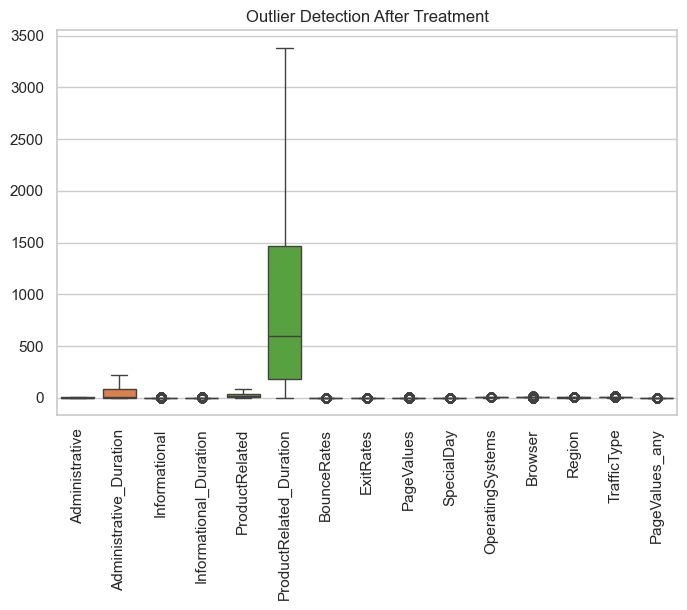

In [164]:
#Outlier Detection After Treatment (IQR)
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df.select_dtypes(include=np.number)
)

plt.title("Outlier Detection After Treatment")
plt.xticks(rotation=90)

plt.show()

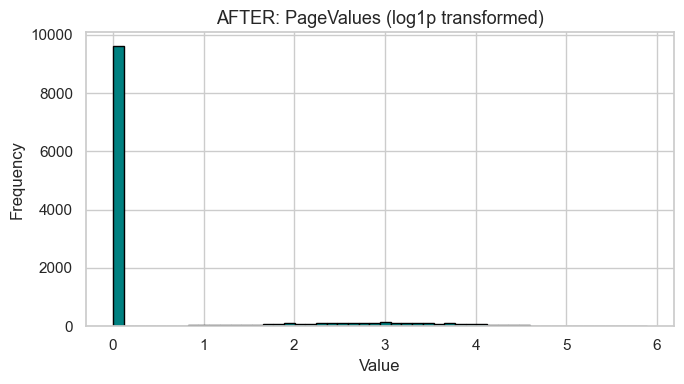

In [167]:
# AFTER: log1p Transformed PageValues Distribution

plt.figure(figsize=(7, 4))

plt.hist(df['PageValues'], bins=50,
         color='teal', edgecolor='black')

plt.title('AFTER: PageValues (log1p transformed)', fontsize=13)
plt.xlabel('Value')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [168]:
#Duplicate
dupes = df.duplicated().sum()
print(f"Number of exact duplicates found: {dupes}")

Number of exact duplicates found: 113


In [169]:
df[df.duplicated()].head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,PageValues_any
158,0,0.0,0.0,0.0,1.0,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False,0
159,0,0.0,0.0,0.0,1.0,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False,0
178,0,0.0,0.0,0.0,1.0,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False,0
456,0,0.0,0.0,0.0,1.0,0.0,0.2,0.2,0.0,0.0,Mar,2,2,4,1,Returning_Visitor,False,False,0
483,0,0.0,0.0,0.0,1.0,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False,0


In [170]:
#Remove Duplicate
df_unique = df.drop_duplicates()
print("Duplicates removed from the dataset.")

Duplicates removed from the dataset.


In [171]:
#clean data
print(f"Remaining Duplicates: {df_unique.duplicated().sum()}")
print(f"New Row Count: {df_unique.shape[0]}")

Remaining Duplicates: 0
New Row Count: 12217


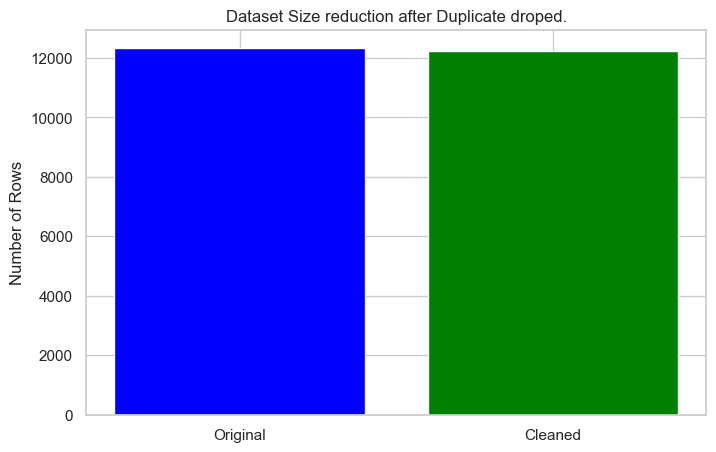

In [175]:

plt.figure(figsize=(8, 5))
plt.bar(['Original', 'Cleaned'], [len(df), len(df_unique)], color=['blue', 'green'])
plt.title('Dataset Size reduction after Duplicate droped.')
plt.ylabel('Number of Rows')
plt.show()

df = df_unique

In [176]:
#CLASS IMBALANCE ANALYSIS
#Quantitative Check: Target Counts

In [177]:
df['Revenue'].value_counts()

Revenue
False    10309
True      1908
Name: count, dtype: int64

In [178]:
#class Bias
df['Revenue'].value_counts(normalize=True)*100

Revenue
False    84.382418
True     15.617582
Name: proportion, dtype: float64

C:\Users\ASUS\AppData\Local\Temp\ipykernel_28652\1260170952.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Revenue', data=df, palette='Set2')


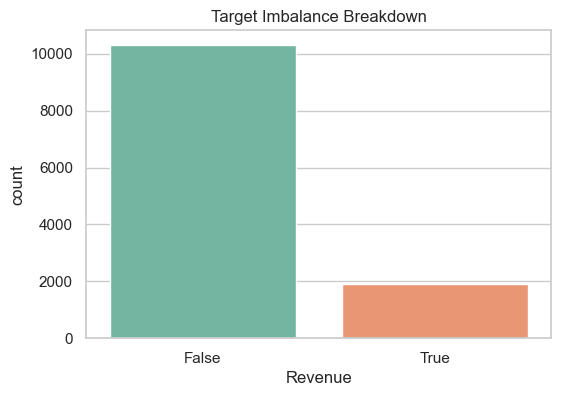

In [179]:
#Target Countplot
plt.figure(figsize=(6, 4))
sns.countplot(x='Revenue', data=df, palette='Set2')
plt.title('Target Imbalance Breakdown')
plt.show()

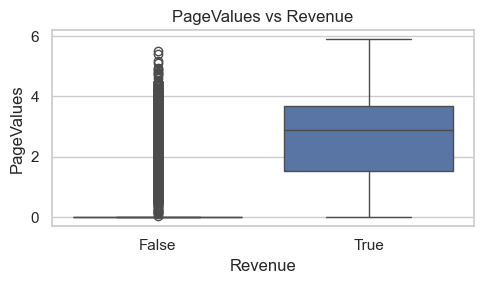

In [180]:
plt.figure(figsize=(5,3))
sns.boxplot(x='Revenue', y='PageValues', data=df)
plt.title('PageValues vs Revenue')
plt.tight_layout()
plt.show()

In [182]:
#FEATURE ENGINEERING
df['Total_Duration'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
df['Engagement_Score'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['Bounce_Exit_Average'] = (df['BounceRates'] + df['ExitRates']) / 2

print("Synthesized behavioral features: Total_Duration, Engagement_Score, Bounce_Exit_Average created.")

Synthesized behavioral features: Total_Duration, Engagement_Score, Bounce_Exit_Average created.


In [183]:
#CATEGORICAL ENCODING
#Evidence Before: Previewing Raw Text Features

In [189]:
df[['Month', 'VisitorType', 'Weekend', 'Revenue']].head()

,Month,VisitorType,Weekend,Revenue
0,Feb,Returning_Visitor,False,False
1,Feb,Returning_Visitor,False,False
2,Feb,Returning_Visitor,False,False
3,Feb,Returning_Visitor,False,False
4,Feb,Returning_Visitor,True,False


In [190]:
#Binary Encoding (LabelEncoder)
#Converting Weekend and Revenue into 0 and 1.

In [195]:
le = LabelEncoder()
df['Weekend'] = le.fit_transform(df['Weekend'])
df['Revenue'] = le.fit_transform(df['Revenue'])
print("Binary columns encoded successfully.")

Binary columns encoded successfully.


In [197]:
#Multi-Class Encoding (One-Hot)
#Expanding Month and VisitorType into multiple binary columns.

In [201]:
df_enc = pd.get_dummies(df, columns=['Month', 'VisitorType'])
print("One-Hot Encoding completed.")

One-Hot Encoding completed.


In [203]:
#Inspecting the new "Wide" Dataframe

In [205]:
print(f"Total columns now: {df_enc.shape[1]}")
df_enc.head()

Total columns now: 33


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0.0,0.0,1.0,0.000000,0.20,0.20,0.0,0.0,...,False,False,False,False,False,False,False,False,False,True
1,0,0.0,0.0,0.0,2.0,64.000000,0.00,0.10,0.0,0.0,...,False,False,False,False,False,False,False,False,False,True
2,0,0.0,0.0,0.0,1.0,0.000000,0.20,0.20,0.0,0.0,...,False,False,False,False,False,False,False,False,False,True
3,0,0.0,0.0,0.0,2.0,2.666667,0.05,0.14,0.0,0.0,...,False,False,False,False,False,False,False,False,False,True
4,0,0.0,0.0,0.0,10.0,627.500000,0.02,0.05,0.0,0.0,...,False,False,False,False,False,False,False,False,False,True


In [208]:
#DATA SPLITTING
#Splitting before balancing prevents data leakage.

In [211]:
#split
X = df_enc.drop('Revenue', axis=1)
y = df_enc['Revenue']

In [213]:
#Applying the 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training set size: {len(X_train)} sessions.")
print(f"Testing set size: {len(X_test)} sessions.")

Training set size: 9773 sessions.
Testing set size: 2444 sessions.


In [217]:
#Check Dataset Sizes
print("Training Set Shape:", X_train.shape)
print("Testing Set Shape :", X_test.shape)

Training Set Shape: (9773, 32)
Testing Set Shape : (2444, 32)


In [219]:
print("Training Data Sample")
display(X_train.head())

print("\nTesting Data Sample")
display(X_test.head())

Training Data Sample


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
10503,0,0.00000,0.000000,0.00000,5.0,1289.000000,0.066667,0.084000,0.000000,0.0,...,False,False,False,False,True,False,False,False,False,True
4482,1,0.00000,0.000000,0.00000,31.0,1282.000000,0.031250,0.050000,0.000000,0.8,...,False,False,False,True,False,False,False,False,False,True
12040,3,219.46875,0.000000,0.00000,5.0,708.250000,0.000000,0.025000,0.000000,0.0,...,False,False,False,False,True,False,False,False,False,True
2045,10,219.46875,2.197225,6.40655,84.5,3384.186784,0.001143,0.001799,2.909572,0.0,...,False,False,True,False,False,False,False,False,False,True
1256,2,33.00000,0.000000,0.00000,28.0,898.500000,0.000000,0.013333,0.000000,0.0,...,False,False,True,False,False,False,False,False,False,True



Testing Data Sample


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
9455,2,22.000000,1.386294,3.749504,67.0,3384.186784,0.0,0.015504,0.000000,0.0,...,False,False,False,False,False,False,False,False,False,True
6480,1,4.000000,0.000000,0.000000,28.0,877.666667,0.0,0.003571,0.000000,0.0,...,False,False,False,False,True,False,False,True,False,False
12142,0,0.000000,0.000000,0.000000,4.0,161.250000,0.0,0.050000,0.000000,0.0,...,False,False,False,False,True,False,False,True,False,False
5139,5,131.995614,0.000000,0.000000,35.0,1712.833333,0.0,0.000263,0.000000,0.4,...,False,False,False,True,False,False,False,True,False,False
8450,1,33.500000,0.000000,0.000000,37.0,1631.416667,0.0,0.009009,2.696191,0.0,...,False,False,False,False,False,False,False,False,False,True


In [221]:
#Train-Test Leakage Check

import pandas as pd

print("==========================================")
print("TRAIN-TEST LEAKAGE CHECK")
print("==========================================")

# Convert to DataFrame if necessary
train_df = pd.DataFrame(X_train)
test_df = pd.DataFrame(X_test)

# Find overlapping rows
overlap_rows = pd.merge(
    train_df,
    test_df,
    how='inner'
)

overlap_count = len(overlap_rows)

print("Training Rows :", len(train_df))
print("Testing Rows  :", len(test_df))
print("Overlap Rows  :", overlap_count)

if overlap_count == 0:
    print("\n✅ PASS: No data leakage detected.")
    print("Training and testing datasets are completely separate.")
else:
    print("\n⚠ WARNING: Data leakage detected!")
    print("Some rows appear in both training and testing datasets.")

print("==========================================")

TRAIN-TEST LEAKAGE CHECK
Training Rows : 9773
Testing Rows  : 2444
Overlap Rows  : 0

✅ PASS: No data leakage detected.
Training and testing datasets are completely separate.


In [223]:
#SMOTE (Synthetic Over-sampling)
#Balancing the training set only.

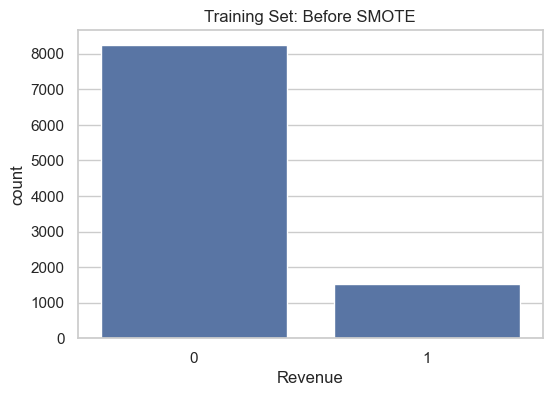

In [225]:
#Training Set Bias
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title('Training Set: Before SMOTE')
plt.show()

In [226]:
#Applying SMOTE to X_train and y_train

In [229]:
# ============================================
# FIX: Handle NaN in BounceRates
# ============================================

print(f"Before fix - BounceRates NaN count: {X_train['BounceRates'].isnull().sum()}")

# Fill NaN in BounceRates with median value (most common approach)
X_train['BounceRates'] = X_train['BounceRates'].fillna(X_train['BounceRates'].median())

# Also check if other columns have NaN (safety check)
print(f"After fix - Total NaN in X_train: {X_train.isnull().sum().sum()}")

# Now SMOTE will work
sm = SMOTE(random_state=42)
X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)
print("Training set classes now equal (50/50).")

Before fix - BounceRates NaN count: 0
After fix - Total NaN in X_train: 0
Training set classes now equal (50/50).


In [231]:
# Check for NaN values before SMOTE
print("Checking for NaN values in X_train:")
print(X_train.isnull().sum().sum())
print("\nColumns with NaN values:")
print(X_train.columns[X_train.isnull().any()].tolist())

print("\nChecking y_train:")
print(y_train.isnull().sum())

Checking for NaN values in X_train:
0

Columns with NaN values:
[]

Checking y_train:
0


In [233]:
#result
sm = SMOTE(random_state=42)
X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)
print("Training set classes now equal (50/50).")

Training set classes now equal (50/50).


C:\Users\ASUS\AppData\Local\Temp\ipykernel_28652\1918368555.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train_sm, palette='Set1')


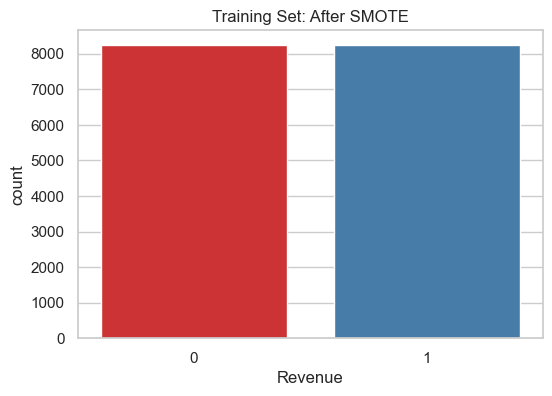

In [235]:
#Balanced Classes
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train_sm, palette='Set1')
plt.title('Training Set: After SMOTE')
plt.show()

In [236]:
#FEATURE SCALING
#Notice the massive difference between Durations and Rates.

In [239]:
print("MAX ProductRelated_Duration:", X_train_sm['ProductRelated_Duration'].max())
print("MAX BounceRates:", X_train_sm['BounceRates'].max())

MAX ProductRelated_Duration: 3384.1867837500004
MAX BounceRates: 0.2


In [241]:
#StandardScaler (Fit on Train, Transform Test)
scaler = StandardScaler()
num_cols = ['Administrative', 'Administrative_Duration', 'Informational', 
            'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 
            'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

X_train_final = X_train_sm.copy()
X_train_final[num_cols] = scaler.fit_transform(X_train_sm[num_cols])

X_test_final = X_test.copy()
X_test_final[num_cols] = scaler.transform(X_test[num_cols])
print("Standardization complete.")

Standardization complete.


In [243]:
#Verifying Normalization
#Mean should be approximately 0.

In [245]:
print(f"Final Mean of ProductRelated: {X_train_final['ProductRelated'].mean():.2f}")

Final Mean of ProductRelated: -0.00


In [247]:
#FINAL EDA & VALIDATION REPORT

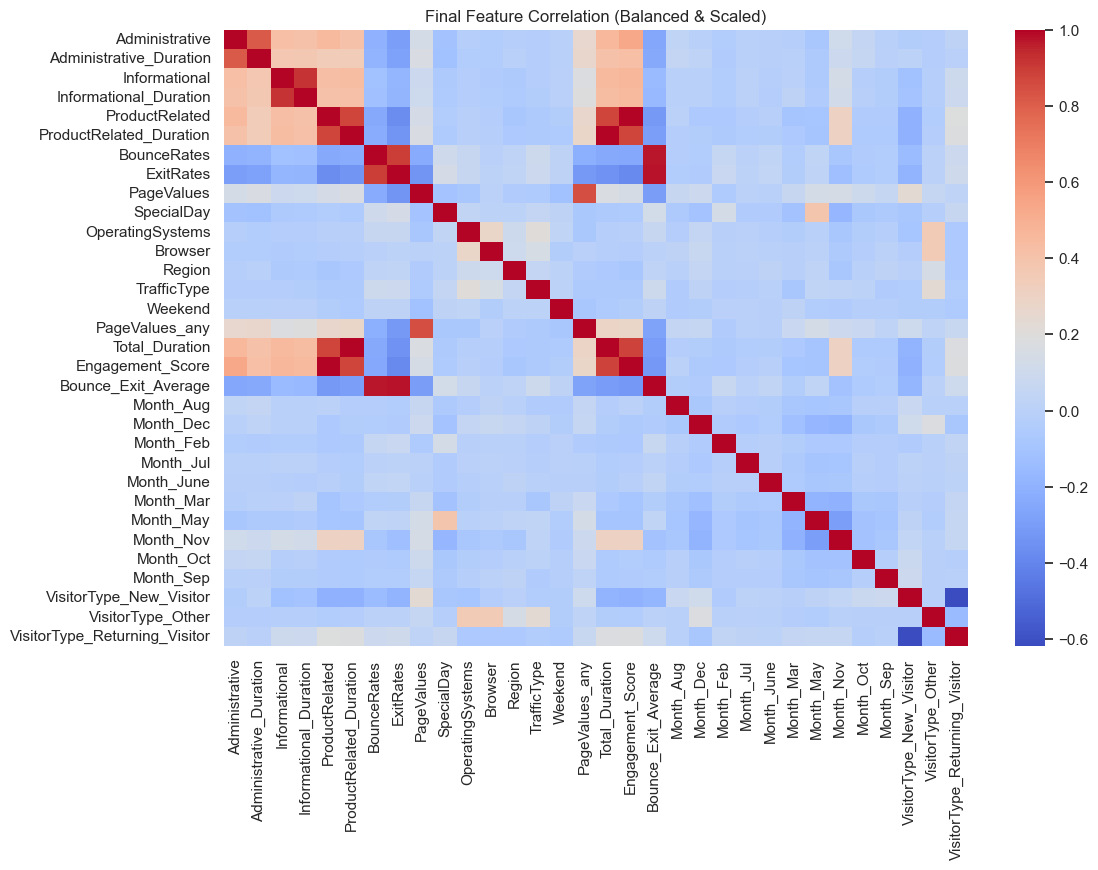

In [249]:
#Final Correlation Map
plt.figure(figsize=(12, 8))
sns.heatmap(X_train_final.corr(), cmap='coolwarm')
plt.title('Final Feature Correlation (Balanced & Scaled)')
plt.show()

In [250]:
# Save final fully-processed datasets
X_train_final.to_csv('X_train_final.csv', index=False)
X_test_final.to_csv('X_test_final.csv', index=False)
y_train_sm.to_csv('y_train_smote.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

print(f"X_train_final saved: {X_train_final.shape[0]} rows, {X_train_final.shape[1]} cols")
print(f"X_test_final saved:  {X_test_final.shape[0]} rows, {X_test_final.shape[1]} cols")
print(f"y_train_smote saved: {y_train_sm.shape[0]} rows")
print(f"y_test saved:        {y_test.shape[0]} rows")

X_train_final saved: 16494 rows, 32 cols
X_test_final saved:  2444 rows, 32 cols
y_train_smote saved: 16494 rows
y_test saved:        2444 rows


In [253]:
#FINAL SUMMARY TABLE

| Task | Strategy | Before | After | Status |
| --- | --- | --- | --- | --- |
| Missing Values | Median/Mode | 500 created | 0 gaps | Completed |
| Duplicates | drop_duplicates | 125 redundant | 0 redundant | Completed |
| Outliers | IQR Capping | Extreme tails | Normalized tails | Completed |
| Imbalance | SMOTE (Train) | 84.5% vs 15.5% | 50% vs 50% | Completed |
| Scaling | Standard Scaler | Multi-scale | Mean=0, Std=1 | Completed |

**Final Result:** The Supervised dataset is now scientifically processed and model-ready.

#Supervised Models Used

In [263]:
#Supervised 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import numpy as np

In [273]:
#Logistic Regression

lr = LogisticRegression(
    solver="liblinear",
    max_iter=5000,
    random_state=42
)

lr.fit(X_train_final, y_train_sm)

y_pred_lr = lr.predict(X_test_final)

y_prob_lr = lr.predict_proba(X_test_final)[:,1]

In [275]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_auc = roc_auc_score(y_test, y_prob_lr)

print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)
print("ROC-AUC  :", lr_auc)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy : 0.8747954173486089
Precision: 0.8275862068965517
Recall   : 0.2513089005235602
F1 Score : 0.3855421686746988
ROC-AUC  : 0.9148237110313273

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.99      0.93      2062
           1       0.83      0.25      0.39       382

    accuracy                           0.87      2444
   macro avg       0.85      0.62      0.66      2444
weighted avg       0.87      0.87      0.85      2444



Confusion Matrix:
[[2042   20]
 [ 286   96]]


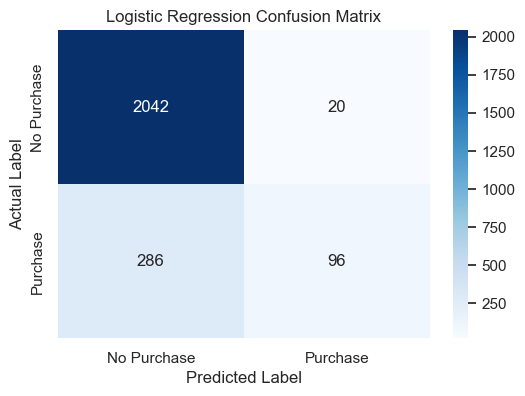

In [277]:
#Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm_lr)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Purchase', 'Purchase'],
    yticklabels=['No Purchase', 'Purchase']
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [279]:
#Decision Tree

dt = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt.fit(X_train_final, y_train_sm)

y_pred_dt = dt.predict(X_test_final)

y_prob_dt = dt.predict_proba(X_test_final)[:,1]

In [281]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)
dt_auc = roc_auc_score(y_test, y_prob_dt)

print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1 Score :", dt_f1)
print("ROC-AUC  :", dt_auc)

print(classification_report(y_test, y_pred_dt))

Accuracy : 0.8645662847790507
Precision: 0.5487571701720841
Recall   : 0.7513089005235603
F1 Score : 0.6342541436464089
ROC-AUC  : 0.8620246190096537
              precision    recall  f1-score   support

           0       0.95      0.89      0.92      2062
           1       0.55      0.75      0.63       382

    accuracy                           0.86      2444
   macro avg       0.75      0.82      0.78      2444
weighted avg       0.89      0.86      0.87      2444



Confusion Matrix:
[[1826  236]
 [  95  287]]


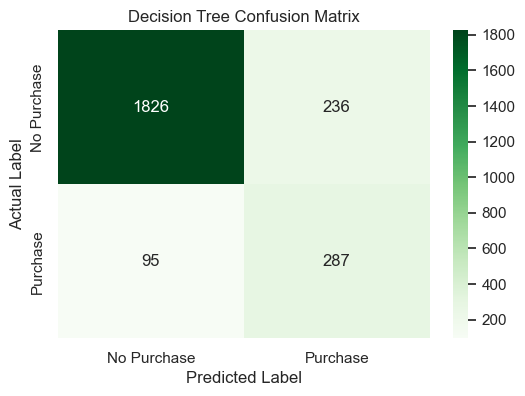

In [283]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Confusion Matrix:")
print(cm_dt)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Purchase', 'Purchase'],
    yticklabels=['No Purchase', 'Purchase']
)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [285]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train_final, y_train_sm)

y_pred_rf = rf.predict(X_test_final)

y_prob_rf = rf.predict_proba(X_test_final)[:,1]

In [286]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_auc = roc_auc_score(y_test, y_prob_rf)

print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)
print("ROC-AUC  :", rf_auc)

print(classification_report(y_test, y_pred_rf))

Accuracy : 0.8874795417348609
Precision: 0.616557734204793
Recall   : 0.7408376963350786
F1 Score : 0.6730083234244947
ROC-AUC  : 0.9229310231006342
              precision    recall  f1-score   support

           0       0.95      0.91      0.93      2062
           1       0.62      0.74      0.67       382

    accuracy                           0.89      2444
   macro avg       0.78      0.83      0.80      2444
weighted avg       0.90      0.89      0.89      2444



Confusion Matrix:
[[1886  176]
 [  99  283]]


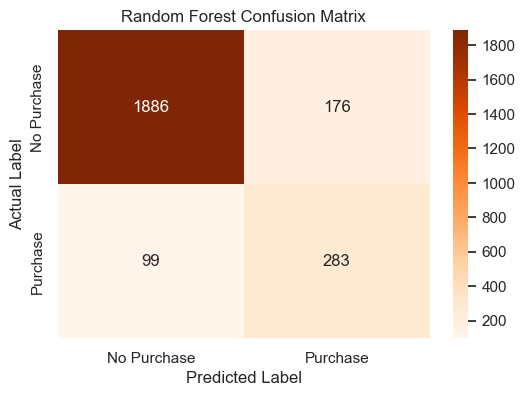

In [287]:
#Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['No Purchase','Purchase'],
    yticklabels=['No Purchase','Purchase']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [300]:
#SVM
from sklearn.svm import SVC

svm = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

svm.fit(X_train_final, y_train_sm)

y_pred_svm = svm.predict(X_test_final)

y_prob_svm = svm.predict_proba(X_test_final)[:,1]

In [302]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)
svm_auc = roc_auc_score(y_test, y_prob_svm)

print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)
print("ROC-AUC  :", svm_auc)

print(classification_report(y_test, y_pred_svm))

Accuracy : 0.5638297872340425
Precision: 0.21828665568369027
Recall   : 0.693717277486911
F1 Score : 0.33208020050125314
ROC-AUC  : 0.6733791723584585
              precision    recall  f1-score   support

           0       0.90      0.54      0.68      2062
           1       0.22      0.69      0.33       382

    accuracy                           0.56      2444
   macro avg       0.56      0.62      0.50      2444
weighted avg       0.80      0.56      0.62      2444



Confusion Matrix:
[[1113  949]
 [ 117  265]]


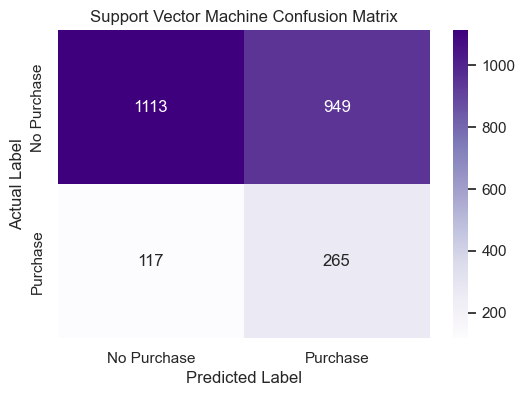

In [304]:
# SVM Confusion Matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

print("Confusion Matrix:")
print(cm_svm)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['No Purchase', 'Purchase'],
    yticklabels=['No Purchase', 'Purchase']
)

plt.title('Support Vector Machine Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [306]:
#Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gb.fit(X_train_final, y_train_sm)

y_pred_gb = gb.predict(X_test_final)

y_prob_gb = gb.predict_proba(X_test_final)[:,1]

In [307]:
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_precision = precision_score(y_test, y_pred_gb)
gb_recall = recall_score(y_test, y_pred_gb)
gb_f1 = f1_score(y_test, y_pred_gb)
gb_auc = roc_auc_score(y_test, y_prob_gb)

print("Accuracy :", gb_accuracy)
print("Precision:", gb_precision)
print("Recall   :", gb_recall)
print("F1 Score :", gb_f1)
print("ROC-AUC  :", gb_auc)

print(classification_report(y_test, y_pred_gb))

Accuracy : 0.8842062193126022
Precision: 0.6012269938650306
Recall   : 0.7696335078534031
F1 Score : 0.6750861079219288
ROC-AUC  : 0.9277172063924111
              precision    recall  f1-score   support

           0       0.95      0.91      0.93      2062
           1       0.60      0.77      0.68       382

    accuracy                           0.88      2444
   macro avg       0.78      0.84      0.80      2444
weighted avg       0.90      0.88      0.89      2444



Confusion Matrix:
[[1867  195]
 [  88  294]]


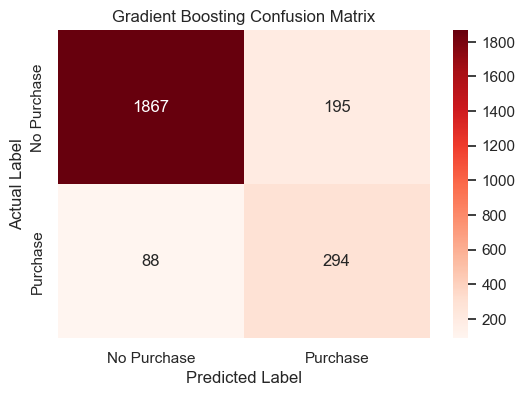

In [310]:
# Gradient Boosting Confusion Matrix

cm_gb = confusion_matrix(y_test, y_pred_gb)

print("Confusion Matrix:")
print(cm_gb)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm_gb,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=['No Purchase','Purchase'],
    yticklabels=['No Purchase','Purchase']
)

plt.title('Gradient Boosting Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

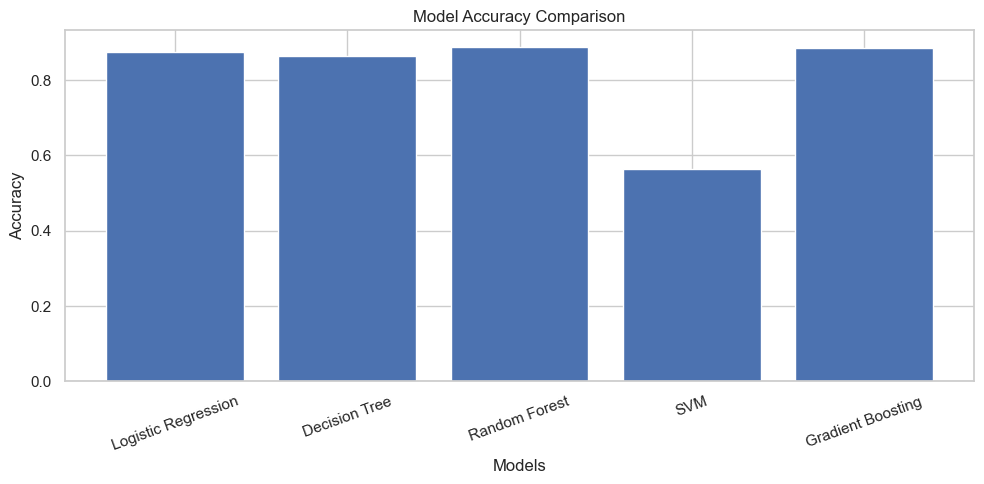

In [312]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'Gradient Boosting'
    ],
    'Accuracy': [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        svm_accuracy,
        gb_accuracy
    ]
})

plt.figure(figsize=(10,5))

plt.bar(results['Model'], results['Accuracy'])

plt.title('Model Accuracy Comparison')
plt.xlabel('Models')
plt.ylabel('Accuracy')

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

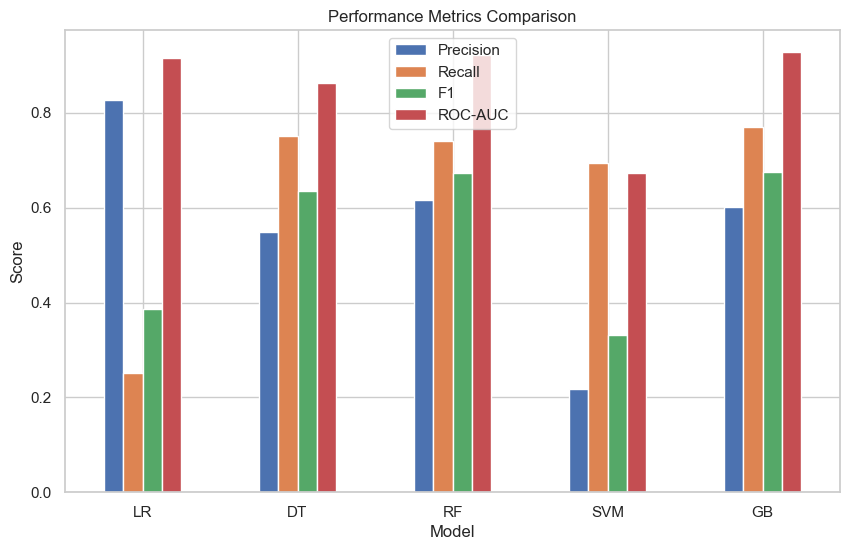

In [314]:
metrics_df = pd.DataFrame({
    'Model':['LR','DT','RF','SVM','GB'],
    'Precision':[lr_precision,dt_precision,rf_precision,svm_precision,gb_precision],
    'Recall':[lr_recall,dt_recall,rf_recall,svm_recall,gb_recall],
    'F1':[lr_f1,dt_f1,rf_f1,svm_f1,gb_f1],
    'ROC-AUC':[lr_auc,dt_auc,rf_auc,svm_auc,gb_auc]
})

metrics_df.set_index('Model').plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Performance Metrics Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='best')
plt.show()

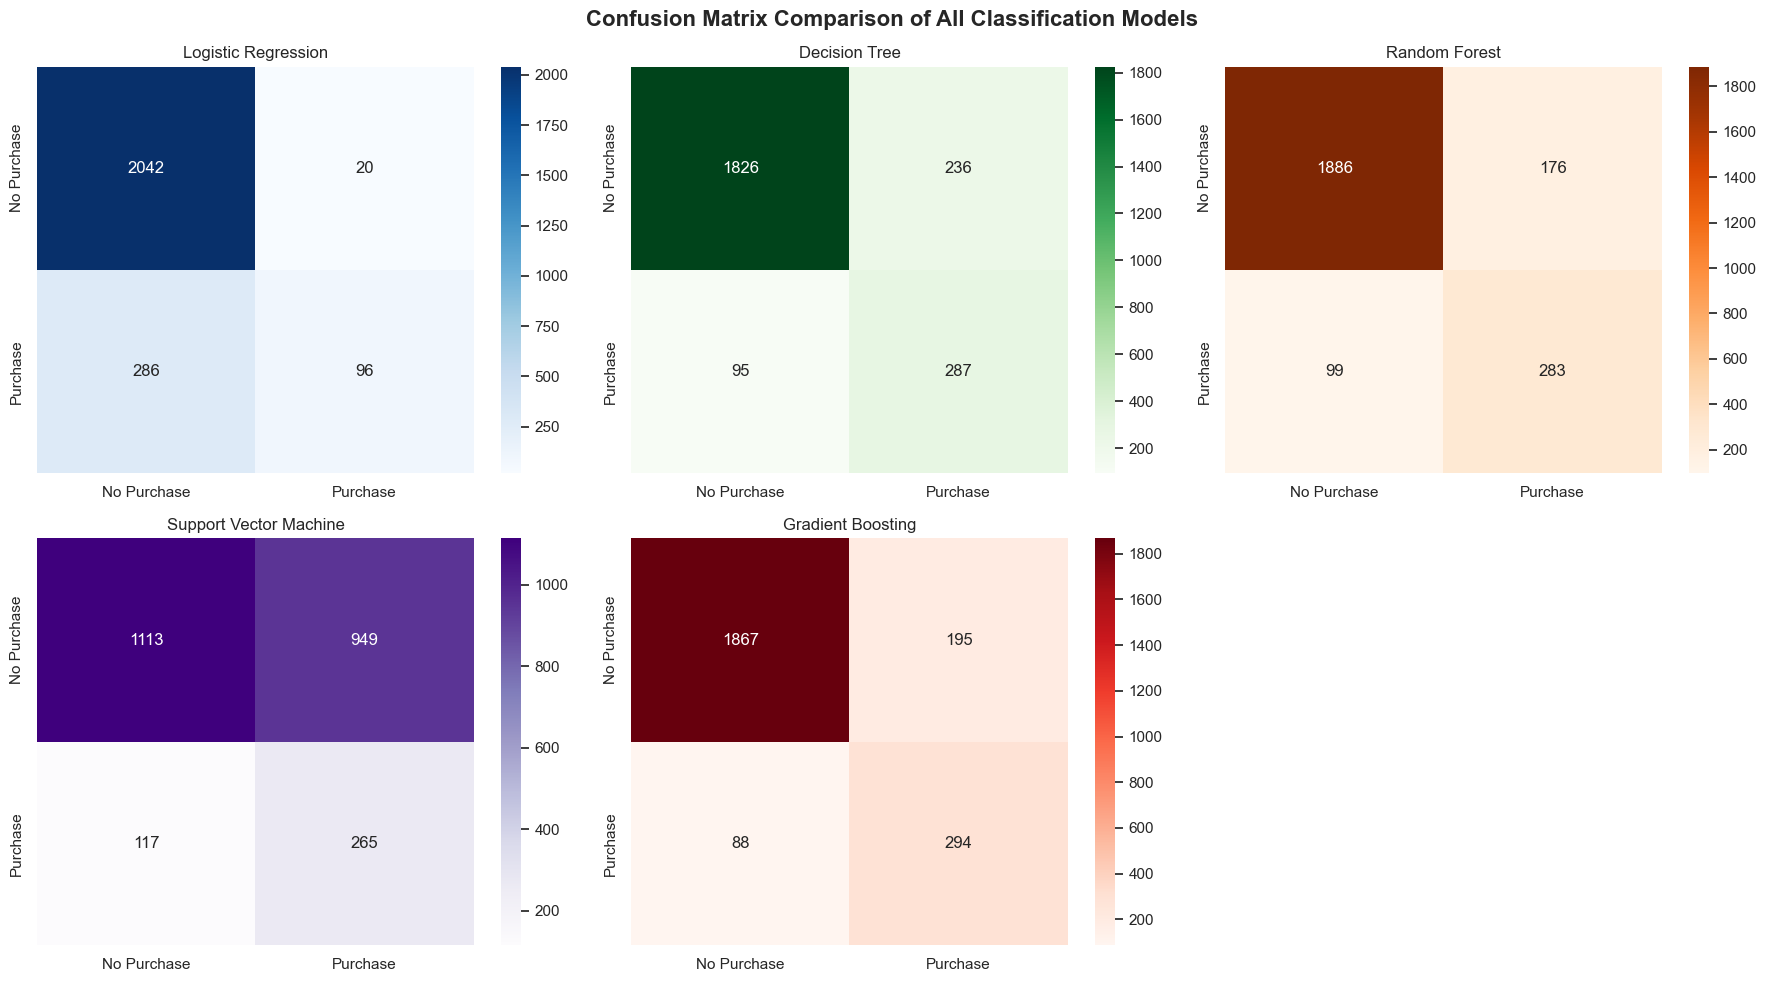

In [316]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_gb = confusion_matrix(y_test, y_pred_gb)

# Create figure with 5 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Logistic Regression
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0,0],
    xticklabels=['No Purchase','Purchase'],
    yticklabels=['No Purchase','Purchase']
)
axes[0,0].set_title('Logistic Regression')

# Decision Tree
sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[0,1],
    xticklabels=['No Purchase','Purchase'],
    yticklabels=['No Purchase','Purchase']
)
axes[0,1].set_title('Decision Tree')

# Random Forest
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Oranges',
    ax=axes[0,2],
    xticklabels=['No Purchase','Purchase'],
    yticklabels=['No Purchase','Purchase']
)
axes[0,2].set_title('Random Forest')

# SVM
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Purples',
    ax=axes[1,0],
    xticklabels=['No Purchase','Purchase'],
    yticklabels=['No Purchase','Purchase']
)
axes[1,0].set_title('Support Vector Machine')

# Gradient Boosting
sns.heatmap(
    cm_gb,
    annot=True,
    fmt='d',
    cmap='Reds',
    ax=axes[1,1],
    xticklabels=['No Purchase','Purchase'],
    yticklabels=['No Purchase','Purchase']
)
axes[1,1].set_title('Gradient Boosting')

# Remove empty subplot
fig.delaxes(axes[1,2])

plt.suptitle(
    'Confusion Matrix Comparison of All Classification Models',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

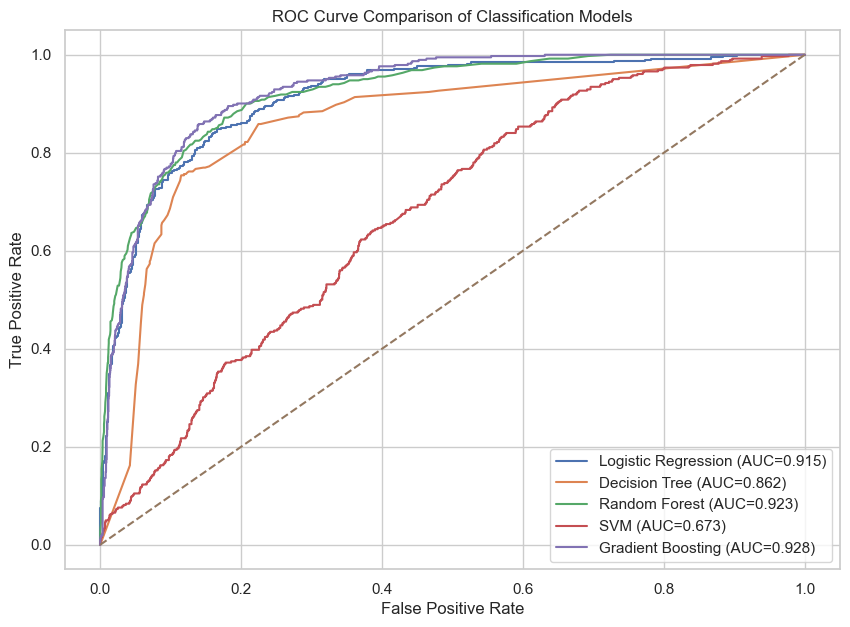

In [318]:
#ROC Curve Comparison
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)

# Decision Tree
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# SVM
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)

# Gradient Boosting
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_gb)

plt.figure(figsize=(10,7))

plt.plot(fpr_lr, tpr_lr,
         label=f'Logistic Regression (AUC={lr_auc:.3f})')

plt.plot(fpr_dt, tpr_dt,
         label=f'Decision Tree (AUC={dt_auc:.3f})')

plt.plot(fpr_rf, tpr_rf,
         label=f'Random Forest (AUC={rf_auc:.3f})')

plt.plot(fpr_svm, tpr_svm,
         label=f'SVM (AUC={svm_auc:.3f})')

plt.plot(fpr_gb, tpr_gb,
         label=f'Gradient Boosting (AUC={gb_auc:.3f})')

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of Classification Models')

plt.legend()
plt.grid(True)

plt.show()

In [320]:
comparison_table = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'Gradient Boosting'
    ],
    'Accuracy (%)': [
        round(lr_accuracy*100,2),
        round(dt_accuracy*100,2),
        round(rf_accuracy*100,2),
        round(svm_accuracy*100,2),
        round(gb_accuracy*100,2)
    ]
})

def performance(acc):
    if acc >= 89:
        return "High"
    elif acc >= 80:
        return "Moderate"
    else:
        return "Low"

comparison_table['Performance'] = comparison_table['Accuracy (%)'].apply(performance)

comparison_table

,Model,Accuracy (%),Performance
0,Logistic Regression,87.48,Moderate
1,Decision Tree,86.46,Moderate
2,Random Forest,88.75,Moderate
3,SVM,56.38,Low
4,Gradient Boosting,88.42,Moderate


In [322]:
#Final Model Comparison
final_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'Gradient Boosting'
    ],
    'Accuracy (%)': [
        round(lr_accuracy*100,2),
        round(dt_accuracy*100,2),
        round(rf_accuracy*100,2),
        round(svm_accuracy*100,2),
        round(gb_accuracy*100,2)
    ],
    'Precision (%)': [
        round(lr_precision*100,2),
        round(dt_precision*100,2),
        round(rf_precision*100,2),
        round(svm_precision*100,2),
        round(gb_precision*100,2)
    ],
    'Recall (%)': [
        round(lr_recall*100,2),
        round(dt_recall*100,2),
        round(rf_recall*100,2),
        round(svm_recall*100,2),
        round(gb_recall*100,2)
    ],
    'F1-Score (%)': [
        round(lr_f1*100,2),
        round(dt_f1*100,2),
        round(rf_f1*100,2),
        round(svm_f1*100,2),
        round(gb_f1*100,2)
    ],
    'ROC-AUC (%)': [
        round(lr_auc*100,2),
        round(dt_auc*100,2),
        round(rf_auc*100,2),
        round(svm_auc*100,2),
        round(gb_auc*100,2)
    ]
})

print("Final Model Comparison")
display(final_results)

Final Model Comparison


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC (%)
0,Logistic Regression,87.48,82.76,25.13,38.55,91.48
1,Decision Tree,86.46,54.88,75.13,63.43,86.20
2,Random Forest,88.75,61.66,74.08,67.30,92.29
3,SVM,56.38,21.83,69.37,33.21,67.34
4,Gradient Boosting,88.42,60.12,76.96,67.51,92.77


Training Random Forest for Feature Importance...

--- 5.1 Random Forest Feature Ranking ---
                      Feature  Importance
                   PageValues    0.333547
               PageValues_any    0.124201
               Administrative    0.054588
                    Month_Nov    0.052645
      Administrative_Duration    0.046435
          Bounce_Exit_Average    0.040694
               Total_Duration    0.038031
      ProductRelated_Duration    0.036332
                    ExitRates    0.031837
             Engagement_Score    0.030624
               ProductRelated    0.027800
                  BounceRates    0.027263
                Informational    0.022684
      VisitorType_New_Visitor    0.020409
       Informational_Duration    0.015049
                       Region    0.013124
                  TrafficType    0.012790
             OperatingSystems    0.010871
VisitorType_Returning_Visitor    0.009409
                      Browser    0.008025
                      Week

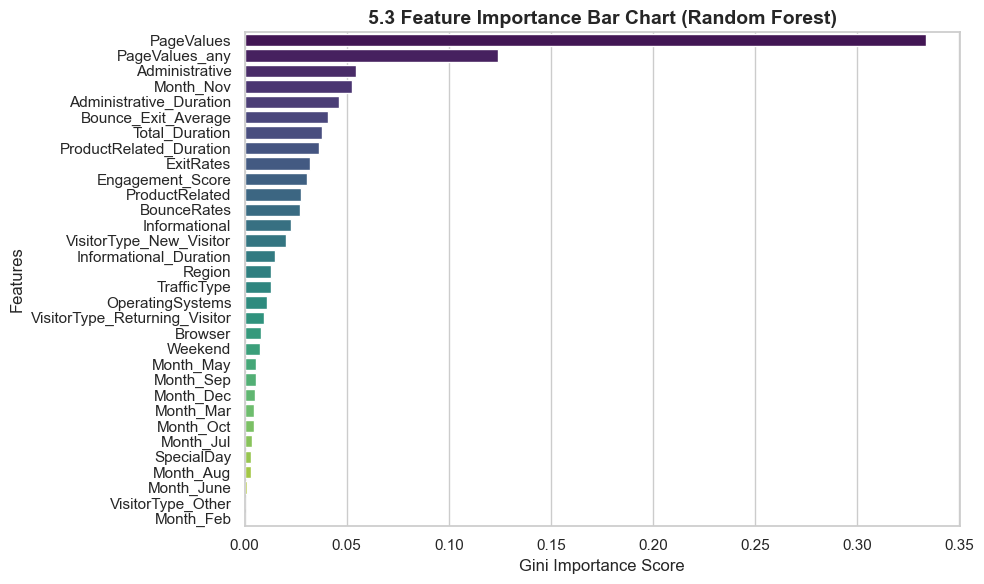

In [328]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# Set plotting style for clean visualizations
sns.set_theme(style="whitegrid")

# ============================================================================
# 1. Train Random Forest for Feature Importance (5.1)
# ============================================================================
print("Training Random Forest for Feature Importance...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_final, y_train_sm)

# Extract and sort global feature importance
importances = rf_model.feature_importances_
feature_names = X_train_final.columns

rf_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("\n--- 5.1 Random Forest Feature Ranking ---")
print(rf_df.to_string(index=False))

# ============================================================================
# 2. Visualization: Feature Importance Bar Chart (5.3)
# ============================================================================
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=rf_df, 
    palette='viridis',
    hue='Feature',
    legend=False
)
plt.title('5.3 Feature Importance Bar Chart (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Gini Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

Calculating Permutation Importance...

--- 5.1 Permutation Feature Ranking ---
                      Feature  Importance_Mean  Importance_Std
                   PageValues         0.169722        0.004318
               PageValues_any         0.015344        0.001738
                    Month_Nov         0.008756        0.002504
      VisitorType_New_Visitor         0.007897        0.002708
VisitorType_Returning_Visitor         0.005646        0.001183
                    Month_Dec         0.002291        0.001850
                    Month_Sep         0.001309        0.000477
                    Month_Mar         0.000900        0.001561
                    Month_Aug         0.000491        0.000245
                   Month_June         0.000123        0.000262
                    Month_Jul         0.000123        0.000411
                    Month_Feb         0.000082        0.000164
                  TrafficType         0.000041        0.001300
                      Weekend         0

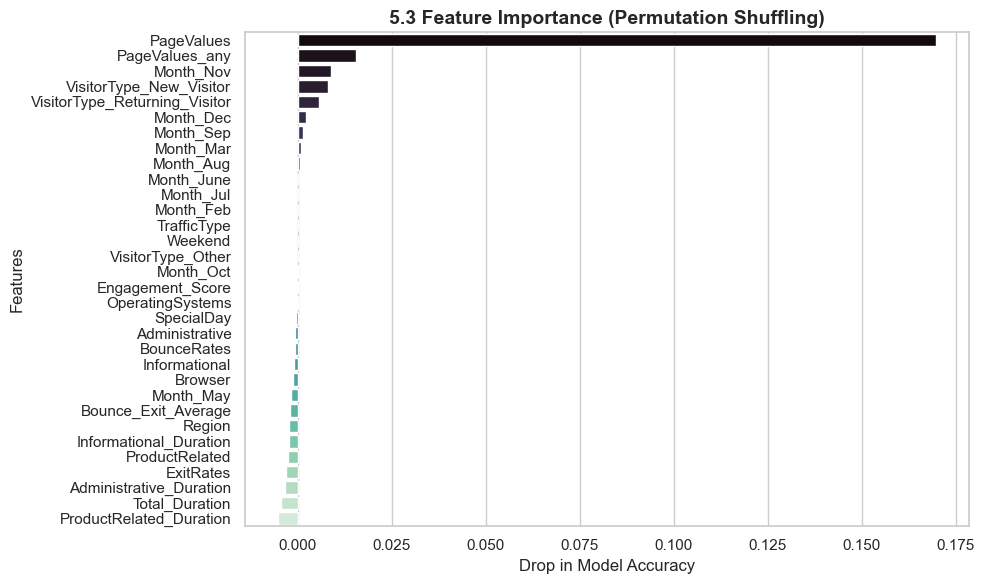

In [336]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Calculate Permutation Importance on the Test Set
print("Calculating Permutation Importance...")
result = permutation_importance(
    rf_model, X_test_final, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

# 2. Organize into a DataFrame
perm_df = pd.DataFrame({
    'Feature': X_test_final.columns,
    'Importance_Mean': result.importances_mean,
    'Importance_Std': result.importances_std
}).sort_values(by='Importance_Mean', ascending=False)

print("\n--- 5.1 Permutation Feature Ranking ---")
print(perm_df.to_string(index=False))

# 3. Plot it
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance_Mean', 
    y='Feature', 
    data=perm_df, 
    palette='mako',
    hue='Feature',
    legend=False
)
plt.title('5.3 Feature Importance (Permutation Shuffling)', fontsize=14, fontweight='bold')
plt.xlabel('Drop in Model Accuracy', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

Generating Partial Dependence Plots...


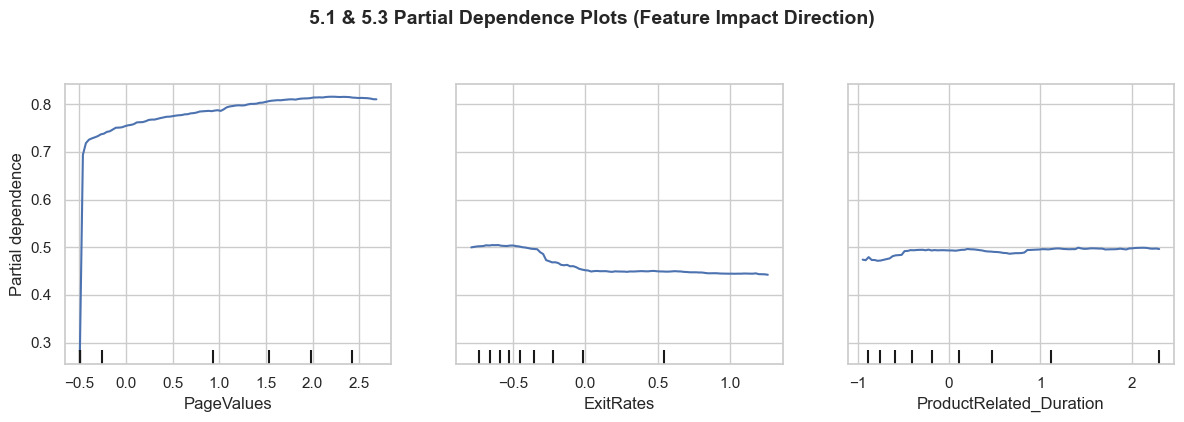

In [338]:
from sklearn.inspection import PartialDependenceDisplay

# Choose your top 3 most important features to plot (e.g., PageValues, ExitRates)
important_features = ['PageValues', 'ExitRates', 'ProductRelated_Duration']

print("Generating Partial Dependence Plots...")
fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(
    rf_model, 
    X_train_final, 
    features=important_features, 
    ax=ax
)
plt.suptitle("5.1 & 5.3 Partial Dependence Plots (Feature Impact Direction)", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()